# Satisfacción y lealtad del cliente en telefonía móvil
## Modelo de ecuaciones estructurales con datos del índice ECSI

**Autores:** Ana Milena Uribe, Alejandro Quintero, Francisco Mario Campo y Pablo Stevens Casilimas. **Curso:** Inferencia Avanzada y Análisis Multivariado, Unidad 3

### Pregunta del proyecto

¿La cadena **imagen → expectativas → calidad percibida → satisfacción → lealtad**, propuesta por los índices nacionales de satisfacción (ACSI y ECSI), explica la permanencia de los clientes de un operador de telefonía móvil?

### Por qué un modelo de ecuaciones estructurales

Los cinco conceptos de la pregunta no se observan directamente: se infieren de respuestas a encuestas que contienen error de medición. Un modelo de ecuaciones estructurales (SEM) resuelve tres problemas a la vez:

1. **Mide** cada concepto como una variable latente a partir de varios indicadores y separa la varianza común del error.
2. **Estima simultáneamente** una red de relaciones donde un constructo es efecto y causa a la vez (la satisfacción depende de la calidad y explica la lealtad), lo que permite evaluar mediaciones.
3. **Contrasta** si la teoría reproduce los datos mediante índices de ajuste, en lugar de asumirla como cierta.

### Flujo del proyecto

| Fase | Pregunta técnica que responde |
|---|---|
| 1. Datos | ¿Los datos son íntegros y qué supuestos de distribución se sostienen? |
| 2. Modelo de medición (CFA) | ¿Los indicadores miden bien cada constructo? |
| 3. Hipótesis | ¿Qué relaciones predice la teoría y en qué dirección? |
| 4. Modelo estructural | ¿Qué relaciones se sostienen con los datos? |
| 5. Mediación | ¿La calidad genera lealtad a través de la satisfacción? |
| 6. Validez | ¿Los constructos convergen, se diferencian y predicen casos nuevos? |
| 7. Trazabilidad | ¿Las cifras del informe coinciden con este cuaderno? |

Estimación por máxima verosimilitud con `semopy` (sintaxis equivalente a `lavaan`). Semilla fija para que todos los resultados sean reproducibles.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.ERROR)      # silencia avisos numéricos internos de semopy

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import semopy

SEMILLA = 2026      # reproducibilidad del bootstrap y de la validación cruzada
N_BOOT = 1000       # remuestras para los intervalos de los efectos indirectos
K_FOLDS = 10        # particiones de la validación predictiva
SALIDA = "resultados"
os.makedirs(SALIDA, exist_ok=True)

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.dpi": 300, "savefig.bbox": "tight"})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("semopy", semopy.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

semopy 2.3.11 | pandas 3.1.0 | numpy 2.5.4


## 1. Datos

### 1.1 Fuente y diccionario

El conjunto proviene del estudio ECSI de telefonía móvil analizado por Tenenhaus et al. (2005) y distribuido en el paquete `seminr` de R: **250 clientes** que respondieron 24 ítems en una escala de **1 a 10**.

El modelo usa **cinco constructos reflectivos**. Dos bloques del ECSI original quedan fuera porque no permiten una medición confiable como factor latente:

- **Valor percibido** (PERV1, PERV2): con dos indicadores, el factor queda apenas identificado y no es posible evaluar su consistencia interna de forma robusta.
- **Quejas** (CUSCO): con un solo indicador no hay variable latente, solo una variable observada sin corrección del error de medición.

In [2]:
datos = pd.read_csv("ecsi_mobi.csv")

CONSTRUCTOS = {
    "IMAG": ("Imagen corporativa", [f"IMAG{i}" for i in range(1, 6)]),
    "CUEX": ("Expectativas", ["CUEX1", "CUEX2", "CUEX3"]),
    "PERQ": ("Calidad percibida", [f"PERQ{i}" for i in range(1, 8)]),
    "CUSA": ("Satisfacción", ["CUSA1", "CUSA2", "CUSA3"]),
    "CUSL": ("Lealtad", ["CUSL1", "CUSL2", "CUSL3"]),
}
NOMBRE = {k: v[0] for k, v in CONSTRUCTOS.items()}
FAC = list(CONSTRUCTOS)
INDICADORES = [x for _, items in CONSTRUCTOS.values() for x in items]

CONTENIDO = {
    "IMAG1": "Confianza en lo que la empresa dice y hace", "IMAG2": "Estabilidad y solidez",
    "IMAG3": "Contribución social", "IMAG4": "Preocupación por los clientes", "IMAG5": "Innovación y visión de futuro",
    "CUEX1": "Calidad global esperada al vincularse", "CUEX2": "Ajuste esperado a las necesidades",
    "CUEX3": "Frecuencia esperada de fallas",
    "PERQ1": "Calidad global percibida", "PERQ2": "Calidad técnica de la red", "PERQ3": "Atención y asesoría",
    "PERQ4": "Calidad de los servicios usados", "PERQ5": "Variedad de productos y servicios",
    "PERQ6": "Confiabilidad y exactitud", "PERQ7": "Claridad de la información",
    "CUSA1": "Satisfacción general", "CUSA2": "Cumplimiento de expectativas", "CUSA3": "Comparación con el proveedor ideal",
    "CUSL1": "Volver a elegir al operador", "CUSL2": "Tolerancia a diferencias de precio", "CUSL3": "Recomendar al operador",
}
diccionario = pd.DataFrame([(NOMBRE[k], i, CONTENIDO[i]) for k, (_, its) in CONSTRUCTOS.items() for i in its],
                           columns=["constructo", "indicador", "contenido"])
diccionario.to_csv(f"{SALIDA}/00_diccionario.csv", sep=";", index=False)
diccionario

,constructo,indicador,contenido
0,Imagen corporativa,IMAG1,Confianza en lo que la empresa dice y hace
1,Imagen corporativa,IMAG2,Estabilidad y solidez
2,Imagen corporativa,IMAG3,Contribución social
3,Imagen corporativa,IMAG4,Preocupación por los clientes
4,Imagen corporativa,IMAG5,Innovación y visión de futuro
5,Expectativas,CUEX1,Calidad global esperada al vincularse
6,Expectativas,CUEX2,Ajuste esperado a las necesidades
7,Expectativas,CUEX3,Frecuencia esperada de fallas
8,Calidad percibida,PERQ1,Calidad global percibida
9,Calidad percibida,PERQ2,Calidad técnica de la red


### 1.2 Calidad de los datos

Antes de modelar se verifica la integridad: faltantes, duplicados, valores fuera de la escala y respuestas sin variación (patrón típico de encuestas respondidas sin atención).

In [3]:
X = datos[INDICADORES].astype(float)
calidad = pd.Series({
    "Observaciones": len(datos),
    "Indicadores del modelo": len(INDICADORES),
    "Valores faltantes": int(X.isna().sum().sum()),
    "Filas duplicadas": int(datos.duplicated().sum()),
    "Valores fuera de 1-10": int(((X < 1) | (X > 10)).sum().sum()),
    "Respuestas sin variación": int((X.nunique(axis=1) == 1).sum()),
}, name="resultado")
calidad.to_csv(f"{SALIDA}/01_calidad_datos.csv", sep=";")
calidad

Observaciones               250
Indicadores del modelo       21
Valores faltantes             0
Filas duplicadas              0
Valores fuera de 1-10         0
Respuestas sin variación      1
Name: resultado, dtype: int64

**Decisión:** la base no requiere imputación ni depuración. El cliente que calificó todos los ítems con el mismo valor se conserva: es una respuesta plausible en una encuesta de satisfacción, y eliminarlo reduciría artificialmente la varianza.

In [4]:
desc = X.describe().T[["mean", "std", "min", "max"]]
desc["asimetria"] = X.skew()
desc["curtosis"] = X.kurt()
desc.to_csv(f"{SALIDA}/02_descriptivos.csv", sep=";")

# Normalidad multivariada: curtosis de Mardia
Z = X - X.mean()
S_inv = np.linalg.inv(np.cov(X.T, bias=True))
d2 = np.einsum("ij,jk,ik->i", Z.values, S_inv, Z.values)
p, n = X.shape[1], X.shape[0]
b2p = np.mean(d2 ** 2)
z_mardia = (b2p - p * (p + 2)) / np.sqrt(8 * p * (p + 2) / n)
print(f"Asimetría univariada: {desc.asimetria.min():.2f} a {desc.asimetria.max():.2f}")
print(f"Curtosis multivariada de Mardia: {b2p:.1f} (esperada bajo normalidad: {p*(p+2)}); z = {z_mardia:.2f}")
desc.round(2)

Asimetría univariada: -1.08 a 0.55
Curtosis multivariada de Mardia: 686.0 (esperada bajo normalidad: 483); z = 51.63


,mean,std,min,max,asimetria,curtosis
IMAG1,7.640,1.700,1.000,10.000,-0.910,1.790
IMAG2,7.780,1.690,1.000,10.000,-0.800,1.040
IMAG3,6.740,2.130,1.000,10.000,-0.800,0.720
IMAG4,7.590,1.840,1.000,10.000,-0.930,1.410
IMAG5,7.930,1.560,1.000,10.000,-1.080,2.810
CUEX1,7.580,1.620,1.000,10.000,-0.670,0.900
CUEX2,7.530,1.790,1.000,10.000,-0.810,1.540
CUEX3,7.420,2.100,1.000,10.000,-0.860,0.680
PERQ1,7.940,1.420,2.000,10.000,-0.730,1.260
PERQ2,7.190,1.890,1.000,10.000,-0.830,0.800


**Lectura:** predominan las calificaciones altas (asimetría negativa), salvo CUSL2, y la curtosis multivariada supera la esperada bajo normalidad. Por eso, además de los errores estándar de máxima verosimilitud, los efectos indirectos se estiman con **bootstrap** (fase 5), que no depende de ese supuesto.

## 2. Modelo de medición: análisis factorial confirmatorio

### 2.1 Especificación

Cada constructo es **reflectivo**: los indicadores son manifestaciones del concepto. Si la satisfacción de un cliente aumenta, se espera que suban a la vez sus tres indicadores, por lo que deben estar correlacionados. Los cinco factores se dejan correlacionar libremente.

In [5]:
MEDICION = "\n".join(f"{k} =~ " + " + ".join(items) for k, (_, items) in CONSTRUCTOS.items())
print(MEDICION)

def indices_ajuste(modelo, datos_obs):
    s = semopy.calc_stats(modelo).T["Value"]
    obs = modelo.vars["observed"]
    S = datos_obs[obs].cov().values
    Sigma = modelo.calc_sigma()[0]
    sd = np.sqrt(np.diag(S))
    tri = np.tril_indices(len(obs))
    srmr = float(np.sqrt(np.mean(((S - Sigma) / np.outer(sd, sd))[tri] ** 2)))
    return pd.Series({"chi2": s["chi2"], "gl": s["DoF"], "p": s["chi2 p-value"], "CFI": s["CFI"],
                      "TLI": s["TLI"], "RMSEA": s["RMSEA"], "SRMR": srmr, "AIC": s["AIC"], "BIC": s["BIC"]})

cfa = semopy.Model(MEDICION)
cfa.fit(X)
ajuste_cfa = indices_ajuste(cfa, X)
ajuste_cfa

IMAG =~ IMAG1 + IMAG2 + IMAG3 + IMAG4 + IMAG5
CUEX =~ CUEX1 + CUEX2 + CUEX3
PERQ =~ PERQ1 + PERQ2 + PERQ3 + PERQ4 + PERQ5 + PERQ6 + PERQ7
CUSA =~ CUSA1 + CUSA2 + CUSA3
CUSL =~ CUSL1 + CUSL2 + CUSL3


chi2    448.385
gl      179.000
p         0.000
CFI       0.880
TLI       0.859
RMSEA     0.078
SRMR      0.056
AIC     100.413
BIC     283.529
dtype: float64

### 2.2 Cargas factoriales

Una carga estandarizada indica cuánto refleja el indicador a su constructo. Como referencia, se esperan cargas de al menos 0,50 y preferiblemente 0,70.

In [6]:
est_cfa = cfa.inspect(std_est=True)
cargas = est_cfa[(est_cfa.op == "~") & (est_cfa.rval.isin(FAC))][["rval", "lval", "Estimate", "Est. Std", "p-value"]].copy()
cargas.columns = ["constructo", "indicador", "carga", "carga_std", "p"]
cargas["p"] = pd.to_numeric(cargas["p"], errors="coerce")
cargas["constructo"] = cargas.constructo.map(NOMBRE)
cargas = cargas.reset_index(drop=True)
cargas.to_csv(f"{SALIDA}/03_cargas_cfa.csv", sep=";", index=False)
cargas

,constructo,indicador,carga,carga_std,p
0,Imagen corporativa,IMAG1,1.000,0.653,NaN
1,Imagen corporativa,IMAG2,0.790,0.520,0.000
2,Imagen corporativa,IMAG3,0.865,0.451,0.000
3,Imagen corporativa,IMAG4,1.117,0.674,0.000
4,Imagen corporativa,IMAG5,0.912,0.650,0.000
5,Expectativas,CUEX1,1.000,0.538,NaN
6,Expectativas,CUEX2,0.987,0.480,0.000
7,Expectativas,CUEX3,0.997,0.414,0.000
8,Calidad percibida,PERQ1,1.000,0.776,NaN
9,Calidad percibida,PERQ2,0.969,0.565,0.000


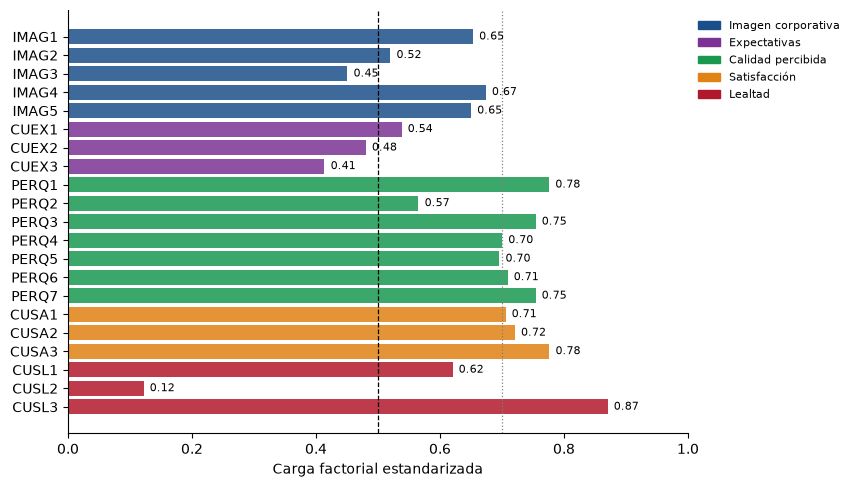

In [7]:
fig, ax = plt.subplots(figsize=(8, 5.5))
colores = {"Imagen corporativa": "#1b4f8a", "Expectativas": "#7b3294", "Calidad percibida": "#1a9850",
           "Satisfacción": "#e08214", "Lealtad": "#b2182b"}
y = np.arange(len(cargas))[::-1]
ax.barh(y, cargas.carga_std, color=[colores[c] for c in cargas.constructo], alpha=0.85)
ax.axvline(0.50, color="black", linestyle="--", linewidth=0.9)
ax.axvline(0.70, color="gray", linestyle=":", linewidth=0.9)
ax.set_yticks(y); ax.set_yticklabels(cargas.indicador)
for yi, v in zip(y, cargas.carga_std):
    ax.text(v + 0.01, yi, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlim(0, 1.0); ax.grid(axis="y", visible=False)
ax.set_xlabel("Carga factorial estandarizada")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colores.values()], labels=list(colores),
          frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
fig.savefig(f"{SALIDA}/fig1_cargas.png"); plt.show()

**Lectura:** Calidad percibida y Satisfacción tienen cargas sólidas. Expectativas tiene sus tres cargas bajas y CUSL2 (tolerancia a diferencias de precio) apenas se relaciona con la lealtad: mide un componente conductual distinto de la intención de recompra y de recomendación.

### 2.3 Fiabilidad y validez convergente

- **Alfa de Cronbach** y **fiabilidad compuesta (CR)**: consistencia interna; referencia CR ≥ 0,70.
- **Varianza media extraída (AVE)**: proporción de varianza de los indicadores que explica el constructo; referencia AVE ≥ 0,50.

In [8]:
def fiabilidad(cargas_std, items):
    lam = cargas_std.values
    cr = lam.sum() ** 2 / (lam.sum() ** 2 + (1 - lam ** 2).sum())
    ave = (lam ** 2).mean()
    k = len(items)
    alfa = k / (k - 1) * (1 - X[items].var(ddof=1).sum() / X[items].sum(axis=1).var(ddof=1))
    return alfa, cr, ave

filas = []
for k, (nombre, items) in CONSTRUCTOS.items():
    lam = cargas.loc[cargas.constructo == nombre, "carga_std"]
    alfa, cr, ave = fiabilidad(lam, items)
    filas.append({"constructo": nombre, "indicadores": len(items), "carga_min": lam.min(), "carga_max": lam.max(),
                  "alfa": alfa, "CR": cr, "AVE": ave, "raiz_AVE": np.sqrt(ave)})
fiab = pd.DataFrame(filas).set_index("constructo")
fiab["CR>=0,70"] = fiab.CR >= 0.70
fiab["AVE>=0,50"] = fiab.AVE >= 0.50
fiab.to_csv(f"{SALIDA}/04_fiabilidad_validez_convergente.csv", sep=";")
fiab

,indicadores,carga_min,carga_max,alfa,CR,AVE,raiz_AVE,"CR>=0,70","AVE>=0,50"
constructo,,,,,,,,,
Imagen corporativa,5,0.451,0.674,0.714,0.729,0.355,0.596,True,False
Expectativas,3,0.414,0.538,0.433,0.470,0.230,0.480,False,False
Calidad percibida,7,0.565,0.776,0.872,0.876,0.505,0.711,True,True
Satisfacción,3,0.706,0.776,0.770,0.779,0.540,0.735,True,True
Lealtad,3,0.122,0.870,0.442,0.585,0.386,0.621,False,False


**Lectura:** solo Calidad percibida y Satisfacción cumplen ambos criterios. Imagen corporativa alcanza la fiabilidad compuesta, pero no el AVE. Expectativas es el constructo peor medido del modelo, lo que anticipa dificultades para detectar sus efectos en la fase estructural.

## 3. Hipótesis estructurales

Las hipótesis se definen **antes** de estimar el modelo estructural y quedan registradas en código, para contrastarlas al final contra los resultados.

In [9]:
HIPOTESIS = pd.DataFrame([
    ("H1", "IMAG", "CUEX", "+", "Una empresa reconocida como confiable e innovadora eleva lo que el cliente espera"),
    ("H2", "IMAG", "PERQ", "+", "La imagen actúa como un sesgo favorable al evaluar la experiencia"),
    ("H3", "CUEX", "PERQ", "+", "Quien espera más tiende a percibir mejor calidad (asimilación, modelo ACSI)"),
    ("H4", "PERQ", "CUSA", "+", "La experiencia de servicio determina el juicio global de satisfacción"),
    ("H5", "CUSA", "CUSL", "+", "Un cliente satisfecho tiene menos motivos para cambiar de operador"),
], columns=["hipotesis", "desde", "hacia", "signo", "fundamento"])
HIPOTESIS["relacion"] = HIPOTESIS.desde.map(NOMBRE) + " → " + HIPOTESIS.hacia.map(NOMBRE)
print("H6 (mediación): Calidad percibida → Satisfacción → Lealtad, efecto indirecto positivo")
HIPOTESIS[["hipotesis", "relacion", "signo", "fundamento"]]

H6 (mediación): Calidad percibida → Satisfacción → Lealtad, efecto indirecto positivo


,hipotesis,relacion,signo,fundamento
0,H1,Imagen corporativa → Expectativas,+,Una empresa reconocida como confiable e innova...
1,H2,Imagen corporativa → Calidad percibida,+,La imagen actúa como un sesgo favorable al eva...
2,H3,Expectativas → Calidad percibida,+,Quien espera más tiende a percibir mejor calid...
3,H4,Calidad percibida → Satisfacción,+,La experiencia de servicio determina el juicio...
4,H5,Satisfacción → Lealtad,+,Un cliente satisfecho tiene menos motivos para...


## 4. Modelo estructural

### 4.1 Modelo de contraste (M1): estructura ECSI completa

M1 añade a la cadena los efectos directos que propone el ECSI completo: imagen y expectativas sobre satisfacción, e imagen sobre lealtad. Se estima para comprobar si esos efectos aportan información o resultan redundantes.

Una solución es **admisible** solo si todos los coeficientes estandarizados están entre −1 y 1; si no, las estimaciones no son interpretables.

In [10]:
M1 = MEDICION + '''
CUEX ~ IMAG
PERQ ~ CUEX
CUSA ~ IMAG + CUEX + PERQ
CUSL ~ IMAG + CUSA
'''
M2 = MEDICION + '''
CUEX ~ IMAG
PERQ ~ IMAG + CUEX
CUSA ~ PERQ
CUSL ~ CUSA
'''

def rutas(modelo):
    e = modelo.inspect(std_est=True)
    r = e[(e.op == "~") & (e.lval.isin(FAC)) & (e.rval.isin(FAC))][["rval", "lval", "Estimate", "Std. Err", "Est. Std", "p-value"]].copy()
    r.columns = ["desde", "hacia", "b", "EE", "beta", "p"]
    r["p"] = pd.to_numeric(r["p"], errors="coerce")
    r["EE"] = pd.to_numeric(r["EE"], errors="coerce")
    r["ruta"] = r.desde.map(NOMBRE) + " → " + r.hacia.map(NOMBRE)
    return r.reset_index(drop=True)

m1 = semopy.Model(M1); m1.fit(X)
r1 = rutas(m1)
r1["|beta| <= 1"] = r1.beta.abs() <= 1
r1[["ruta", "b", "EE", "beta", "p", "|beta| <= 1"]]

,ruta,b,EE,beta,p,|beta| <= 1
0,Imagen corporativa → Expectativas,0.694,0.108,0.992,0.000,True
1,Expectativas → Calidad percibida,1.465,0.208,0.988,0.000,True
2,Imagen corporativa → Satisfacción,1.678,4.092,2.041,0.682,False
3,Expectativas → Satisfacción,-0.970,6.473,-0.825,0.881,True
4,Calidad percibida → Satisfacción,-0.191,0.820,-0.241,0.816,True
5,Imagen corporativa → Lealtad,-4.936,4.936,-3.201,0.317,False
6,Satisfacción → Lealtad,7.524,6.128,4.011,0.220,False


In [11]:
e_m1 = semopy.Model(MEDICION); e_m1.fit(X)
e = e_m1.inspect(std_est=True)
corr_lat = pd.DataFrame(np.eye(5), index=FAC, columns=FAC)
for _, r in e[(e.op == "~~") & e.lval.isin(FAC) & e.rval.isin(FAC) & (e.lval != e.rval)].iterrows():
    corr_lat.loc[r.lval, r.rval] = corr_lat.loc[r.rval, r.lval] = r["Est. Std"]
corr_lat.index = corr_lat.columns = [NOMBRE[k] for k in FAC]
corr_lat.to_csv(f"{SALIDA}/05_correlaciones_latentes.csv", sep=";")
print("Correlaciones entre constructos (CFA):")
corr_lat.round(3)

Correlaciones entre constructos (CFA):


,Imagen corporativa,Expectativas,Calidad percibida,Satisfacción,Lealtad
Imagen corporativa,1.000,0.832,0.927,0.913,0.734
Expectativas,0.832,1.000,0.857,0.822,0.610
Calidad percibida,0.927,0.857,1.000,0.959,0.658
Satisfacción,0.913,0.822,0.959,1.000,0.861
Lealtad,0.734,0.610,0.658,0.861,1.000


**Diagnóstico de M1:** aparecen coeficientes mayores que 1 en valor absoluto y con signo contrario a la teoría, y ninguna ruta hacia Satisfacción o Lealtad es significativa. La matriz de correlaciones latentes muestra la causa: Calidad, Satisfacción e Imagen están correlacionadas por encima de 0,90. Cuando predictores casi redundantes compiten por explicar la misma variable, sus coeficientes se vuelven inestables (**multicolinealidad entre constructos**). M1 no es interpretable.

### 4.2 Modelo final (M2): cadena de mediación

M2 asigna a cada constructo sus antecedentes teóricamente más próximos: la imagen y las expectativas forman la calidad percibida, la calidad genera satisfacción y la satisfacción genera lealtad. Es más parsimonioso y evita que predictores redundantes compitan entre sí.

In [12]:
m2 = semopy.Model(M2); m2.fit(X)
r2 = rutas(m2)
r2["significativa_5%"] = r2.p < 0.05
r2.to_csv(f"{SALIDA}/06_rutas_M2.csv", sep=";", index=False)
r2[["ruta", "b", "EE", "beta", "p", "significativa_5%"]]

,ruta,b,EE,beta,p,significativa_5%
0,Imagen corporativa → Expectativas,0.648,0.104,0.832,0.000,True
1,Imagen corporativa → Calidad percibida,0.722,0.183,0.733,0.000,True
2,Expectativas → Calidad percibida,0.315,0.242,0.249,0.193,False
3,Calidad percibida → Satisfacción,0.742,0.067,0.926,0.000,True
4,Satisfacción → Lealtad,1.488,0.201,0.795,0.000,True


In [13]:
ajuste = pd.DataFrame({"CFA (medición)": ajuste_cfa, "M1 contraste": indices_ajuste(m1, X),
                       "M2 final": indices_ajuste(m2, X)}).T
ajuste["admisible"] = ["Sí", "Sí" if (r1.beta.abs() <= 1).all() else "No (|β| > 1)",
                       "Sí" if (r2.beta.abs() <= 1).all() else "No"]
ajuste.to_csv(f"{SALIDA}/07_indices_ajuste.csv", sep=";")
ajuste

,chi2,gl,p,CFI,TLI,RMSEA,SRMR,AIC,BIC,admisible
CFA (medición),448.385,179.000,0.000,0.880,0.859,0.078,0.056,100.413,283.529,Sí
M1 contraste,459.518,182.000,0.000,0.877,0.858,0.078,0.057,94.324,266.875,No (|β| > 1)
M2 final,468.487,184.000,0.000,0.873,0.856,0.079,0.058,90.252,255.761,Sí


**Lectura del ajuste:** RMSEA y SRMR están por debajo de 0,08 (ajuste absoluto aceptable); CFI y TLI quedan por debajo de 0,90 (ajuste incremental marginal). El χ² es significativo, algo esperable con 250 casos y 21 indicadores. M2 tiene el menor AIC: logra un ajuste equivalente a M1 con menos parámetros y con una solución admisible.

In [14]:
e2 = m2.inspect(std_est=True)
r2_endo = pd.Series({NOMBRE[k]: 1 - e2[(e2.op == "~~") & (e2.lval == k) & (e2.rval == k)]["Est. Std"].iloc[0]
                     for k in ["CUEX", "PERQ", "CUSA", "CUSL"]}, name="R²")
r2_endo.to_csv(f"{SALIDA}/08_r2.csv", sep=";")
r2_endo

Expectativas        0.692
Calidad percibida   0.904
Satisfacción        0.858
Lealtad             0.632
Name: R², dtype: float64

### 4.3 Sensibilidad: ¿conviene retirar CUSL2?

Antes de aceptar el indicador más débil, se re-estima M2 sin él. Si el ajuste no mejora de forma relevante, se conserva para mantener la cobertura del constructo con tres indicadores.

In [15]:
m2b = semopy.Model(M2.replace(" + CUSL2", "")); m2b.fit(X)
pd.DataFrame({"M2 con CUSL2": ajuste.loc["M2 final", ["CFI", "TLI", "RMSEA", "SRMR"]],
              "M2 sin CUSL2": indices_ajuste(m2b, X)[["CFI", "TLI", "RMSEA", "SRMR"]]})

,M2 con CUSL2,M2 sin CUSL2
CFI,0.873,0.875
TLI,0.856,0.856
RMSEA,0.079,0.082
SRMR,0.058,0.058


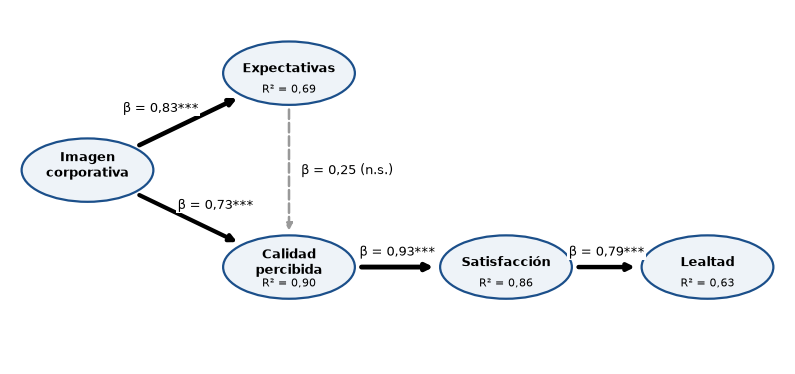

In [16]:
def diagrama(rutas_df, r2s, archivo):
    pos = {"IMAG": (0.10, 0.62), "CUEX": (0.36, 0.88), "PERQ": (0.36, 0.36), "CUSA": (0.64, 0.36), "CUSL": (0.90, 0.36)}
    fig, ax = plt.subplots(figsize=(10, 4.6)); ax.set_xlim(0, 1); ax.set_ylim(0.1, 1.05); ax.axis("off")
    for k, (x, y) in pos.items():
        ax.add_patch(Ellipse((x, y), 0.17, 0.17, facecolor="#eef3f8", edgecolor="#1b4f8a", linewidth=1.6))
        ax.text(x, y + 0.012, NOMBRE[k].replace(" ", "\n", 1), ha="center", va="center", fontsize=9, fontweight="bold")
        if NOMBRE[k] in r2s:
            ax.text(x, y - 0.052, f"R² = {r2s[NOMBRE[k]]:.2f}".replace(".", ","), ha="center", fontsize=8)
    for _, r in rutas_df.iterrows():
        (x0, y0), (x1, y1) = pos[r.desde], pos[r.hacia]
        v = np.array([x1 - x0, y1 - y0]); u = v / np.linalg.norm(v)
        p0 = np.array([x0, y0]) + u * 0.09; p1 = np.array([x1, y1]) - u * 0.09
        sig = r.p < 0.05
        ax.annotate("", xy=p1, xytext=p0, arrowprops=dict(arrowstyle="-|>", lw=1.2 + 2.5 * abs(r.beta),
                    color="black" if sig else "#999999", linestyle="-" if sig else "--"))
        mx, my = (p0 + p1) / 2
        if abs(u[0]) < 0.2: mx += 0.075
        elif abs(u[1]) > 0.2: mx, my = np.array([mx, my]) + np.array([-u[1], u[0]]) * 0.05
        else: my += 0.04
        marca = "***" if r.p < 0.001 else "**" if r.p < 0.01 else "*" if r.p < 0.05 else " (n.s.)"
        ax.text(mx, my, f"β = {r.beta:.2f}{marca}".replace(".", ",", 1), ha="center", va="center", fontsize=9,
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
    fig.savefig(archivo); plt.show()

diagrama(r2, r2_endo.to_dict(), f"{SALIDA}/fig2_modelo_estructural.png")

## 5. Mediación: efectos indirectos con bootstrap

Un efecto indirecto es el producto de dos o más coeficientes, y su distribución no es normal. Por eso su intervalo de confianza se obtiene con **bootstrap por percentiles**: se re-estima el modelo en 1000 remuestras con reemplazo y se toman los percentiles 2,5 y 97,5. Si el intervalo no incluye el cero, la mediación es significativa.

In [17]:
def efectos(modelo):
    e = modelo.inspect(std_est=True)
    b = {(r.rval, r.lval): r["Est. Std"] for _, r in e[(e.op == "~") & e.lval.isin(FAC) & e.rval.isin(FAC)].iterrows()}
    g = lambda a, c: b.get((a, c), 0.0)
    imag_perq = g("IMAG", "PERQ") + g("IMAG", "CUEX") * g("CUEX", "PERQ")
    return {
        "Calidad → Satisfacción → Lealtad": g("PERQ", "CUSA") * g("CUSA", "CUSL"),
        "Imagen → Calidad → Satisfacción": imag_perq * g("PERQ", "CUSA"),
        "Imagen → ... → Lealtad (indirecto total)": imag_perq * g("PERQ", "CUSA") * g("CUSA", "CUSL"),
        "Expectativas → Calidad → Satisfacción": g("CUEX", "PERQ") * g("PERQ", "CUSA"),
    }

puntual = efectos(m2)
rng = np.random.default_rng(SEMILLA)
boot = []
for _ in range(N_BOOT):
    muestra = X.iloc[rng.integers(0, len(X), len(X))].reset_index(drop=True)
    mb = semopy.Model(M2)
    try:
        mb.fit(muestra); boot.append(efectos(mb))
    except Exception:
        pass
boot = pd.DataFrame(boot)
indirectos = pd.DataFrame({"efecto": puntual, "IC95_inf": boot.quantile(0.025), "IC95_sup": boot.quantile(0.975)})
indirectos["significativo"] = (indirectos.IC95_inf > 0) | (indirectos.IC95_sup < 0)
indirectos.to_csv(f"{SALIDA}/09_efectos_indirectos_bootstrap.csv", sep=";")
print(f"Remuestras válidas: {len(boot)} de {N_BOOT}")
indirectos

Remuestras válidas: 1000 de 1000


,efecto,IC95_inf,IC95_sup,significativo
Calidad → Satisfacción → Lealtad,0.736,0.594,0.853,True
Imagen → Calidad → Satisfacción,0.871,0.789,0.935,True
Imagen → ... → Lealtad (indirecto total),0.692,0.542,0.817,True
Expectativas → Calidad → Satisfacción,0.231,-0.444,0.969,False


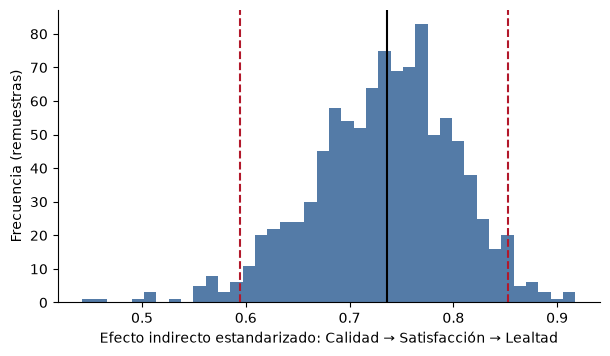

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.8))
clave = "Calidad → Satisfacción → Lealtad"
ax.hist(boot[clave], bins=40, color="#1b4f8a", alpha=0.75)
for q in indirectos.loc[clave, ["IC95_inf", "IC95_sup"]]:
    ax.axvline(q, color="#b2182b", linestyle="--")
ax.axvline(puntual[clave], color="black", linewidth=1.5)
ax.set_xlabel("Efecto indirecto estandarizado: Calidad → Satisfacción → Lealtad")
ax.set_ylabel("Frecuencia (remuestras)")
fig.savefig(f"{SALIDA}/fig3_bootstrap_indirecto.png"); plt.show()

**Lectura:** la calidad influye en la lealtad a través de la satisfacción, con un intervalo que no incluye el cero. La influencia de la imagen sobre la lealtad también es indirecta. En cambio, el efecto de las expectativas tiene un intervalo muy amplio que incluye el cero: es coherente con su baja fiabilidad.

## 6. Validez del modelo

### 6.1 Validez discriminante

Dos criterios complementarios:

- **Fornell-Larcker:** la raíz del AVE de cada constructo debe superar su correlación con cualquier otro constructo.
- **HTMT** (heterotrait-monotrait): valores mayores que 0,85 (criterio estricto) o 0,90 (criterio liberal) indican que dos constructos no se distinguen.

In [19]:
fl = corr_lat.copy()
for nombre in fl.index:
    fl.loc[nombre, nombre] = fiab.loc[nombre, "raiz_AVE"]
fl.to_csv(f"{SALIDA}/10_fornell_larcker.csv", sep=";")

viol = []
for i, a in enumerate(fl.index):
    for b in fl.index[:i]:
        if abs(fl.loc[a, b]) > min(fl.loc[a, a], fl.loc[b, b]):
            viol.append((a, b, round(fl.loc[a, b], 3)))
print("Diagonal: raíz del AVE. Fuera de la diagonal: correlación entre constructos.")
print(f"Pares que violan Fornell-Larcker: {len(viol)} de 10")
for v in viol: print("  ", v)
fl.round(3)

Diagonal: raíz del AVE. Fuera de la diagonal: correlación entre constructos.
Pares que violan Fornell-Larcker: 10 de 10
   ('Expectativas', 'Imagen corporativa', np.float64(0.832))
   ('Calidad percibida', 'Imagen corporativa', np.float64(0.927))
   ('Calidad percibida', 'Expectativas', np.float64(0.857))
   ('Satisfacción', 'Imagen corporativa', np.float64(0.913))
   ('Satisfacción', 'Expectativas', np.float64(0.822))
   ('Satisfacción', 'Calidad percibida', np.float64(0.959))
   ('Lealtad', 'Imagen corporativa', np.float64(0.734))
   ('Lealtad', 'Expectativas', np.float64(0.61))
   ('Lealtad', 'Calidad percibida', np.float64(0.658))
   ('Lealtad', 'Satisfacción', np.float64(0.861))


,Imagen corporativa,Expectativas,Calidad percibida,Satisfacción,Lealtad
Imagen corporativa,0.596,0.832,0.927,0.913,0.734
Expectativas,0.832,0.480,0.857,0.822,0.610
Calidad percibida,0.927,0.857,0.711,0.959,0.658
Satisfacción,0.913,0.822,0.959,0.735,0.861
Lealtad,0.734,0.610,0.658,0.861,0.621


In [20]:
R = X.corr()
def htmt(a, b):
    ia, ib = CONSTRUCTOS[a][1], CONSTRUCTOS[b][1]
    mono = lambda it: (R.loc[it, it].values.sum() - len(it)) / (len(it) * (len(it) - 1))
    return R.loc[ia, ib].values.mean() / np.sqrt(mono(ia) * mono(ib))

htmt_m = pd.DataFrame(np.nan, index=FAC, columns=FAC)
for i, a in enumerate(FAC):
    for b in FAC[:i]:
        htmt_m.loc[a, b] = htmt(a, b)
htmt_m.index = htmt_m.columns = [NOMBRE[k] for k in FAC]
htmt_m.to_csv(f"{SALIDA}/11_htmt.csv", sep=";")
print(f"Pares con HTMT > 0,90: {int((htmt_m > 0.90).sum().sum())} de 10 | > 0,85: {int((htmt_m > 0.85).sum().sum())} de 10")
htmt_m.round(3)

Pares con HTMT > 0,90: 4 de 10 | > 0,85: 8 de 10


,Imagen corporativa,Expectativas,Calidad percibida,Satisfacción,Lealtad
Imagen corporativa,NaN,NaN,NaN,NaN,NaN
Expectativas,0.888,NaN,NaN,NaN,NaN
Calidad percibida,0.929,0.878,NaN,NaN,NaN
Satisfacción,0.910,0.865,0.954,NaN,NaN
Lealtad,0.867,0.770,0.723,0.957,NaN


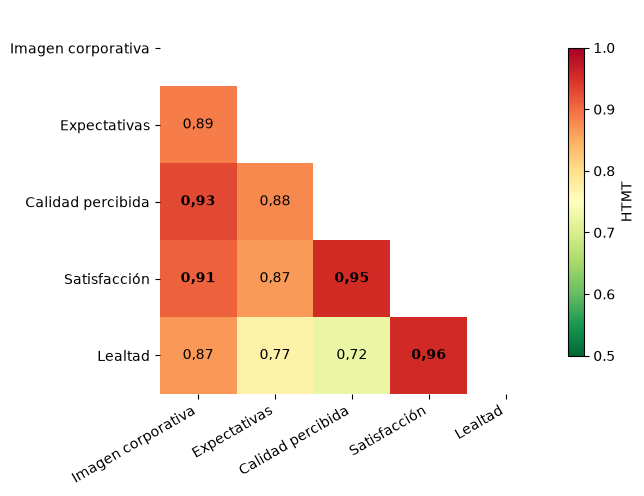

In [21]:
fig, ax = plt.subplots(figsize=(6.2, 5))
vals = htmt_m.values
im = ax.imshow(vals, cmap="RdYlGn_r", vmin=0.5, vmax=1.0)
for i in range(5):
    for j in range(5):
        if not np.isnan(vals[i, j]):
            ax.text(j, i, f"{vals[i, j]:.2f}".replace(".", ","), ha="center", va="center", fontsize=10,
                    fontweight="bold" if vals[i, j] > 0.90 else "normal")
ax.set_xticks(range(5)); ax.set_yticks(range(5))
ax.set_xticklabels(htmt_m.columns, rotation=30, ha="right"); ax.set_yticklabels(htmt_m.index)
for sp in ax.spines.values(): sp.set_visible(False)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8).set_label("HTMT")
fig.savefig(f"{SALIDA}/fig4_htmt.png"); plt.show()

**Lectura:** la validez discriminante no se sostiene entre Calidad, Satisfacción y Lealtad. Los clientes no distinguen con claridad entre la calidad que perciben y su satisfacción global: es un **efecto de halo**, frecuente cuando todas las percepciones se miden en una misma encuesta. Explica tanto la solución impropia de M1 como la magnitud de la ruta Calidad → Satisfacción.

### 6.2 Validez predictiva fuera de muestra

El R² mide capacidad explicativa dentro de la muestra; no garantiza que el modelo prediga casos nuevos. Se aplica una **validación cruzada de 10 particiones**, con la lógica de PLSpredict (Shmueli et al., 2019):

1. Se estima M2 con 9 particiones.
2. Con la matriz de covarianzas implicada por el modelo se predicen los indicadores de Satisfacción y Lealtad de la partición reservada a partir de los indicadores de Imagen, Expectativas y Calidad: E[y | x] = μ_y + Σ_yx Σ_xx⁻¹ (x − μ_x).
3. Se compara contra la **media** de entrenamiento (Q²_predict) y contra una **regresión lineal** con los mismos predictores.

Q²_predict > 0 indica que el modelo predice mejor que la media; un RMSE igual o menor que el de la regresión indica que la estructura teórica no sacrifica capacidad predictiva.

In [22]:
PRED = CONSTRUCTOS["IMAG"][1] + CONSTRUCTOS["CUEX"][1] + CONSTRUCTOS["PERQ"][1]
OBJ = CONSTRUCTOS["CUSA"][1] + CONSTRUCTOS["CUSL"][1]
idx = np.random.default_rng(SEMILLA).permutation(len(X))
pliegues = np.array_split(idx, K_FOLDS)
err = {"SEM": [], "Regresión": [], "Media": []}
for k in range(K_FOLDS):
    test = X.iloc[pliegues[k]]; train = X.drop(X.index[pliegues[k]])
    mk = semopy.Model(M2); mk.fit(train)
    obs = mk.vars["observed"]; Sig = pd.DataFrame(mk.calc_sigma()[0], index=obs, columns=obs)
    mu = train.mean()
    B = Sig.loc[OBJ, PRED].values @ np.linalg.inv(Sig.loc[PRED, PRED].values)
    pred_sem = mu[OBJ].values + (test[PRED].values - mu[PRED].values) @ B.T
    coef = np.linalg.lstsq(np.c_[np.ones(len(train)), train[PRED].values], train[OBJ].values, rcond=None)[0]
    pred_lm = np.c_[np.ones(len(test)), test[PRED].values] @ coef
    y = test[OBJ].values
    err["SEM"].append((y - pred_sem) ** 2); err["Regresión"].append((y - pred_lm) ** 2)
    err["Media"].append((y - mu[OBJ].values) ** 2)
sse = {m: np.vstack(v) for m, v in err.items()}
predictiva = pd.DataFrame({
    "RMSE_SEM": np.sqrt(sse["SEM"].mean(0)), "RMSE_regresion": np.sqrt(sse["Regresión"].mean(0)),
    "RMSE_media": np.sqrt(sse["Media"].mean(0)), "Q2_predict": 1 - sse["SEM"].sum(0) / sse["Media"].sum(0),
}, index=OBJ)
predictiva["SEM <= regresión"] = predictiva.RMSE_SEM <= predictiva.RMSE_regresion
predictiva.to_csv(f"{SALIDA}/12_validez_predictiva.csv", sep=";")
predictiva

,RMSE_SEM,RMSE_regresion,RMSE_media,Q2_predict,SEM <= regresión
CUSA1,0.927,0.941,1.238,0.439,True
CUSA2,1.327,1.353,1.774,0.440,True
CUSA3,1.275,1.280,1.754,0.471,True
CUSL1,2.428,2.541,2.670,0.173,True
CUSL2,2.844,2.918,2.850,0.004,True
CUSL3,1.861,1.931,2.220,0.297,True


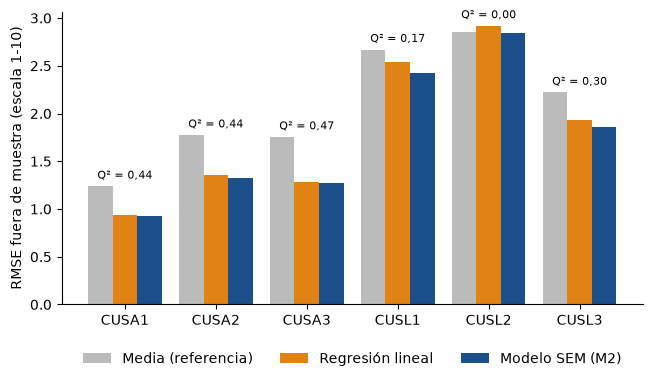

In [23]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
xi = np.arange(len(OBJ)); w = 0.27
ax.bar(xi - w, predictiva.RMSE_media, w, label="Media (referencia)", color="#bbbbbb")
ax.bar(xi, predictiva.RMSE_regresion, w, label="Regresión lineal", color="#e08214")
ax.bar(xi + w, predictiva.RMSE_SEM, w, label="Modelo SEM (M2)", color="#1b4f8a")
for i, q in enumerate(predictiva.Q2_predict):
    ax.text(i, max(predictiva.RMSE_media.iloc[i], predictiva.RMSE_regresion.iloc[i]) + 0.08,
            f"Q² = {q:.2f}".replace(".", ","), ha="center", fontsize=8)
ax.set_xticks(xi); ax.set_xticklabels(OBJ)
ax.set_ylabel("RMSE fuera de muestra (escala 1-10)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.savefig(f"{SALIDA}/fig5_validez_predictiva.png"); plt.show()

## 7. Contraste de hipótesis

Se comparan las hipótesis registradas en la fase 3 con las estimaciones de M2. Una hipótesis se apoya si la ruta es significativa al 5 % y tiene el signo esperado.

In [24]:
contraste = HIPOTESIS.merge(r2[["desde", "hacia", "b", "EE", "beta", "p"]], on=["desde", "hacia"], how="left")
contraste["decision"] = np.where((contraste.p < 0.05) & (contraste.beta > 0), "Apoyada", "No apoyada")
h6 = indirectos.loc["Calidad → Satisfacción → Lealtad"]
contraste = pd.concat([contraste, pd.DataFrame([{
    "hipotesis": "H6", "relacion": "Calidad → Satisfacción → Lealtad (indirecto)", "signo": "+",
    "beta": h6.efecto, "decision": "Apoyada" if h6.significativo and h6.efecto > 0 else "No apoyada",
    "fundamento": f"IC 95 % bootstrap [{h6.IC95_inf:.3f}; {h6.IC95_sup:.3f}]"}])], ignore_index=True)
contraste[["hipotesis", "relacion", "b", "EE", "beta", "p", "decision"]].to_csv(f"{SALIDA}/13_contraste_hipotesis.csv", sep=";", index=False)
contraste[["hipotesis", "relacion", "b", "EE", "beta", "p", "decision", "fundamento"]]

,hipotesis,relacion,b,EE,beta,p,decision,fundamento
0,H1,Imagen corporativa → Expectativas,0.648,0.104,0.832,0.000,Apoyada,Una empresa reconocida como confiable e innova...
1,H2,Imagen corporativa → Calidad percibida,0.722,0.183,0.733,0.000,Apoyada,La imagen actúa como un sesgo favorable al eva...
2,H3,Expectativas → Calidad percibida,0.315,0.242,0.249,0.193,No apoyada,Quien espera más tiende a percibir mejor calid...
3,H4,Calidad percibida → Satisfacción,0.742,0.067,0.926,0.000,Apoyada,La experiencia de servicio determina el juicio...
4,H5,Satisfacción → Lealtad,1.488,0.201,0.795,0.000,Apoyada,Un cliente satisfecho tiene menos motivos para...
5,H6,Calidad → Satisfacción → Lealtad (indirecto),NaN,NaN,0.736,NaN,Apoyada,IC 95 % bootstrap [0.594; 0.853]


**Conclusión del proyecto:** se sostiene la cadena central del modelo (la imagen forma la calidad percibida, la calidad genera satisfacción y la satisfacción genera lealtad), con una mediación significativa. No se sostiene el papel de las expectativas sobre la calidad ni los efectos directos del ECSI completo. Las limitaciones principales son la medición débil de Expectativas y Lealtad y el efecto de halo entre Calidad y Satisfacción; ambas orientan las mejoras del instrumento.

## 8. Trazabilidad con el informe

Cada cifra citada en el informe escrito se recalcula aquí y se compara con el valor publicado, redondeado como aparece en el texto. Si algún valor no coincide, el informe debe corregirse antes de entregarse.

In [25]:
fl_cal_sat = abs(corr_lat.loc["Calidad percibida", "Satisfacción"])
cit = [
    # (sección del informe, cifra, valor calculado, valor publicado, decimales)
    ("Datos", "Observaciones", len(X), 250, 0),
    ("Datos", "Asimetría mínima", desc.asimetria.min(), -1.08, 2),
    ("Datos", "Asimetría máxima", desc.asimetria.max(), 0.55, 2),
    ("CFA", "χ² CFA", ajuste.loc["CFA (medición)", "chi2"], 448.4, 1),
    ("CFA", "gl CFA", ajuste.loc["CFA (medición)", "gl"], 179, 0),
    ("CFA", "CFI CFA", ajuste.loc["CFA (medición)", "CFI"], 0.880, 3),
    ("CFA", "TLI CFA", ajuste.loc["CFA (medición)", "TLI"], 0.859, 3),
    ("CFA", "RMSEA CFA", ajuste.loc["CFA (medición)", "RMSEA"], 0.078, 3),
    ("CFA", "SRMR CFA", ajuste.loc["CFA (medición)", "SRMR"], 0.056, 3),
    ("CFA", "AIC CFA", ajuste.loc["CFA (medición)", "AIC"], 100.4, 1),
    ("CFA", "Carga CUSL2", cargas.set_index("indicador").loc["CUSL2", "carga_std"], 0.12, 2),
    ("CFA", "p CUSL2", cargas.set_index("indicador").loc["CUSL2", "p"], 0.079, 3),
]
for nombre, a, cr, ave in [("Imagen corporativa", .71, .73, .36), ("Expectativas", .43, .47, .23),
                           ("Calidad percibida", .87, .88, .51), ("Satisfacción", .77, .78, .54), ("Lealtad", .44, .59, .39)]:
    cit += [("CFA", f"α {nombre}", fiab.loc[nombre, "alfa"], a, 2), ("CFA", f"CR {nombre}", fiab.loc[nombre, "CR"], cr, 2),
            ("CFA", f"AVE {nombre}", fiab.loc[nombre, "AVE"], ave, 2)]
for nombre, lo, hi in [("Imagen corporativa", .45, .67), ("Expectativas", .41, .54), ("Calidad percibida", .57, .78),
                       ("Satisfacción", .71, .78), ("Lealtad", .12, .87)]:
    cit += [("CFA", f"Carga mín. {nombre}", fiab.loc[nombre, "carga_min"], lo, 2),
            ("CFA", f"Carga máx. {nombre}", fiab.loc[nombre, "carga_max"], hi, 2)]
for mod, chi, gl, cfi, tli, rmsea, srmr, aic in [("M1 contraste", 459.5, 182, .877, .858, .078, .057, 94.3),
                                                  ("M2 final", 468.5, 184, .873, .856, .079, .058, 90.3)]:
    for k, v, d in [("chi2", chi, 1), ("gl", gl, 0), ("CFI", cfi, 3), ("TLI", tli, 3), ("RMSEA", rmsea, 3),
                    ("SRMR", srmr, 3), ("AIC", aic, 1)]:
        cit.append(("Estructural", f"{k} {mod}", ajuste.loc[mod, k], v, d))
b1 = r1.set_index("ruta").beta
cit += [("Estructural", "β M1 Imagen → Satisfacción", b1["Imagen corporativa → Satisfacción"], 2.04, 2),
        ("Estructural", "β M1 Imagen → Lealtad", b1["Imagen corporativa → Lealtad"], -3.20, 2),
        ("Estructural", "β M1 Satisfacción → Lealtad", b1["Satisfacción → Lealtad"], 4.01, 2)]
pub = {"H1": (.65, .10, .83), "H2": (.72, .18, .73), "H3": (.32, .24, .25), "H4": (.74, .07, .93), "H5": (1.49, .20, .79)}
ch = contraste.set_index("hipotesis")
for h, (b, ee, be) in pub.items():
    cit += [("Hipótesis", f"b {h}", ch.loc[h, "b"], b, 2), ("Hipótesis", f"EE {h}", ch.loc[h, "EE"], ee, 2),
            ("Hipótesis", f"β {h}", ch.loc[h, "beta"], be, 2)]
cit += [("Hipótesis", "p H3", ch.loc["H3", "p"], 0.193, 3),
        ("Mediación", "Indirecto H6", h6.efecto, 0.74, 2), ("Mediación", "IC inf H6", h6.IC95_inf, 0.59, 2),
        ("Mediación", "IC sup H6", h6.IC95_sup, 0.85, 2),
        ("Mediación", "Indirecto Imagen → Lealtad", indirectos.iloc[2].efecto, 0.69, 2),
        ("Mediación", "IC inf Imagen → Lealtad", indirectos.iloc[2].IC95_inf, 0.54, 2),
        ("Mediación", "IC sup Imagen → Lealtad", indirectos.iloc[2].IC95_sup, 0.82, 2)]
for nombre, v in [("Expectativas", .69), ("Calidad percibida", .90), ("Satisfacción", .86), ("Lealtad", .63)]:
    cit.append(("Estructural", f"R² {nombre}", r2_endo[nombre], v, 2))
cit += [("Validez", "Pares HTMT > 0,90", int((htmt_m > 0.90).sum().sum()), 4, 0),
        ("Validez", "HTMT Satisfacción-Lealtad", htmt_m.loc["Lealtad", "Satisfacción"], 0.96, 2),
        ("Validez", "HTMT Calidad-Satisfacción", htmt_m.loc["Satisfacción", "Calidad percibida"], 0.95, 2),
        ("Validez", "Correlación Calidad-Satisfacción", fl_cal_sat, 0.96, 2),
        ("Validez", "Raíz AVE Calidad", fiab.loc["Calidad percibida", "raiz_AVE"], 0.71, 2),
        ("Validez", "Raíz AVE Satisfacción", fiab.loc["Satisfacción", "raiz_AVE"], 0.73, 2),
        ("Validez", "Pares que violan Fornell-Larcker", len(viol), 10, 0),
        ("Validez", "Q² mínimo", predictiva.Q2_predict.min(), 0.004, 3),
        ("Validez", "Q² máximo", predictiva.Q2_predict.max(), 0.47, 2),
        ("Validez", "Indicadores con SEM <= regresión", int(predictiva["SEM <= regresión"].sum()), 6, 0)]

traz = pd.DataFrame(cit, columns=["seccion", "cifra", "calculado", "informe", "decimales"])
traz["coincide"] = [round(float(c), int(d)) == round(float(i), int(d)) for c, i, d in zip(traz.calculado, traz.informe, traz.decimales)]
traz.to_csv(f"{SALIDA}/14_trazabilidad_informe.csv", sep=";", index=False)
print(f"Cifras verificadas: {len(traz)} | Coinciden: {int(traz.coincide.sum())} | Diferencias: {int((~traz.coincide).sum())}")
traz[~traz.coincide] if (~traz.coincide).any() else traz.groupby("seccion").coincide.agg(["count", "sum"])

Cifras verificadas: 90 | Coinciden: 90 | Diferencias: 0


,count,sum
seccion,,
CFA,34,34
Datos,3,3
Estructural,21,21
Hipótesis,16,16
Mediación,6,6
Validez,10,10
